In [1]:
import qiskit

In [3]:
print(qiskit.__version__)

1.4.2


In [5]:
from qiskit.transpiler import CouplingMap
grid_coupling = CouplingMap(couplinglist=[
    (0, 1), (1, 2),    # Ligne 1
    (3, 4), (4, 5),    # Ligne 2
    (0, 3), (1, 4), (2, 5)  # Connexions verticales
])

In [7]:
print(grid_coupling)

[[0, 1], [1, 2], [3, 4], [4, 5], [0, 3], [1, 4], [2, 5]]


In [9]:
from qiskit import QuantumCircuit
qc = QuantumCircuit(6)

# Exemple : Appliquer une porte Hadamard sur tous les qubits et des CNOT entre voisins
for i in range(6):
    qc.h(i)
qc.cx(0, 1)
qc.cx(1, 2)
qc.cx(3, 4)
qc.cx(4, 5)
qc.cx(0, 3)
qc.cx(1, 4)
qc.cx(2, 5)

qc.measure_all()
print(qc)

        ┌───┐                          ░ ┌─┐               
   q_0: ┤ H ├──■─────────■─────────────░─┤M├───────────────
        ├───┤┌─┴─┐       │             ░ └╥┘┌─┐            
   q_1: ┤ H ├┤ X ├──■────┼────■────────░──╫─┤M├────────────
        ├───┤└───┘┌─┴─┐  │    │        ░  ║ └╥┘┌─┐         
   q_2: ┤ H ├─────┤ X ├──┼────┼────■───░──╫──╫─┤M├─────────
        ├───┤     └───┘┌─┴─┐  │    │   ░  ║  ║ └╥┘┌─┐      
   q_3: ┤ H ├──■───────┤ X ├──┼────┼───░──╫──╫──╫─┤M├──────
        ├───┤┌─┴─┐     └───┘┌─┴─┐  │   ░  ║  ║  ║ └╥┘┌─┐   
   q_4: ┤ H ├┤ X ├──■───────┤ X ├──┼───░──╫──╫──╫──╫─┤M├───
        ├───┤└───┘┌─┴─┐     └───┘┌─┴─┐ ░  ║  ║  ║  ║ └╥┘┌─┐
   q_5: ┤ H ├─────┤ X ├──────────┤ X ├─░──╫──╫──╫──╫──╫─┤M├
        └───┘     └───┘          └───┘ ░  ║  ║  ║  ║  ║ └╥┘
meas: 6/══════════════════════════════════╩══╩══╩══╩══╩══╩═
                                          0  1  2  3  4  5 


In [70]:
from qiskit import QuantumCircuit, QuantumRegister, transpile
from qiskit.transpiler import CouplingMap, Layout

# Étape 1 : Définir un registre de qubits logiques
qr = QuantumRegister(8, "q")  # Registre logique avec 6 qubits
qc = QuantumCircuit(qr)  # Circuit quantique utilisant ce registre

# Exemple de portes pour illustrer
for i in range(6):
    qc.h(qr[i])
qc.cx(qr[0], qr[1])
qc.cx(qr[1], qr[2])
qc.cx(qr[3], qr[4])
qc.cx(qr[4], qr[5])
qc.cx(qr[0], qr[3])
qc.cx(qr[1], qr[4])
qc.cx(qr[2], qr[5])
qc.cx(qr[0], qr[5])
qc.measure_all()

# Étape 2 : Définir la topologie en grille
coupling_map = CouplingMap([(0, 1), (0, 2), (1, 3), (2, 3), (1, 4), (3, 6), (4, 6), (4, 5), (5, 7), (6, 7)])

# Étape 3 : Créer un initial_layout avec des objets qubits
initial_layout = Layout({qr[0]: 0, qr[1]: 1, qr[2]: 2, qr[3]: 3, qr[4]: 4, qr[5]: 5, qr[6]: 6, qr[7]: 7})

# Étape 4 : Transpiler le circuit
transpiled_circuit = transpile(qc, coupling_map=coupling_map, initial_layout=initial_layout)

# Afficher le circuit transpilé
print("\nCircuit transpilé :")
print(transpiled_circuit)
print(qc)



Circuit transpilé :
         ┌───┐                                          ┌───┐          ┌───┐ ░ »
q_0 -> 0 ┤ H ├──■─────────────────■───────────────────X─┤ H ├──■────■──┤ H ├─░─»
         ├───┤┌─┴─┐             ┌─┴─┐                 │ ├───┤  │  ┌─┴─┐├───┤ ░ »
q_1 -> 1 ┤ H ├┤ X ├─X────────■──┤ X ├──────────────X──X─┤ H ├──┼──┤ X ├┤ H ├─░─»
         └───┘└───┘ │        │  └───┘              │    └───┘┌─┴─┐├───┤└───┘ ░ »
q_2 -> 2 ───────────┼────────┼────■────────────────┼─────────┤ X ├┤ H ├──────░─»
         ┌───┐      │ ┌───┐  │  ┌─┴─┐┌───┐         │         └───┘└───┘      ░ »
q_3 -> 3 ┤ H ├──────X─┤ H ├──┼──┤ X ├┤ H ├──■──────┼─────────────────────────░─»
         ├───┤        └───┘┌─┴─┐└───┘└───┘  │      │                         ░ »
q_4 -> 4 ┤ H ├─────────────┤ X ├──■────X────┼───X──X─────────────────────────░─»
         ├───┤             └───┘┌─┴─┐  │    │   │                            ░ »
q_5 -> 5 ┤ H ├──────────────────┤ X ├──┼────┼───X────────────────────────────░─»
       


=== Coupling Map ===


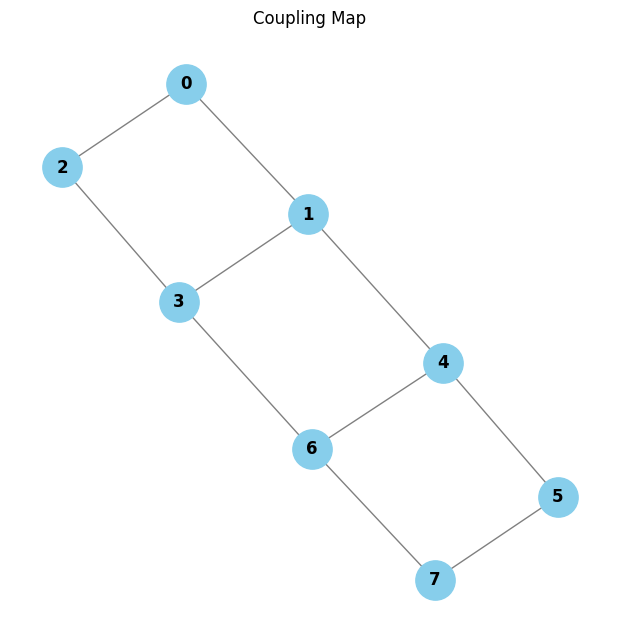


=== Circuit logique ===
        ┌───┐     ┌───┐     ┌───┐                                             »
   q_0: ┤ X ├─────┤ X ├─────┤ X ├──────────────────────■──────────────────────»
        ├───┤     └─┬─┘     └─┬─┘               ┌───┐  │       ┌───┐     ┌───┐»
   q_1: ┤ H ├──■────■────■────┼────■────■────■──┤ X ├──┼───────┤ X ├─────┤ X ├»
        ├───┤  │         │    │    │    │  ┌─┴─┐└─┬─┘  │       └─┬─┘     └─┬─┘»
   q_2: ┤ X ├──┼─────────┼────┼────┼────┼──┤ X ├──┼────┼─────────┼─────────┼──»
        ├───┤┌─┴─┐       │    │  ┌─┴─┐  │  ├───┤  │    │         │         │  »
   q_3: ┤ H ├┤ X ├───────┼────┼──┤ X ├──┼──┤ X ├──■────┼─────────┼────■────┼──»
        ├───┤├───┤       │    │  └───┘  │  └─┬─┘       │  ┌───┐  │    │    │  »
   q_4: ┤ H ├┤ X ├───────┼────┼─────────┼────┼─────────┼──┤ X ├──┼────┼────■──»
        ├───┤└─┬─┘       │    │       ┌─┴─┐  │         │  └─┬─┘  │    │       »
   q_5: ┤ X ├──┼─────────┼────┼───────┤ X ├──┼────■────┼────┼────■────┼───────»
        ├───┤  

In [559]:
from qiskit import QuantumCircuit, QuantumRegister, transpile
from qiskit.transpiler import CouplingMap, Layout, PassManager
from qiskit.transpiler.passes.routing import SabreSwap
from qiskit.transpiler.passes import SetLayout
import random

import networkx as nx
import matplotlib.pyplot as plt

def draw_coupling_map(coupling_map):
    G = nx.Graph()

    # Ajouter les arêtes au graphe
    G.add_edges_from(coupling_map.get_edges())

    # Définir la disposition (placement des noeuds)
    pos = nx.spring_layout(G, seed=42)  # Pour un placement stable

    # Affichage
    plt.figure(figsize=(6, 6))
    nx.draw(G, pos, with_labels=True, node_color='skyblue', node_size=800, font_weight='bold', edge_color='gray')
    plt.title("Coupling Map")
    plt.show()

def generate_random_quantum_circuit(num_qubits: int):
    # 1. Registre logique
    qr = QuantumRegister(num_qubits, "q")
    qc = QuantumCircuit(qr)

    # 2. Génération aléatoire de portes logiques
    for i in range(num_qubits):
        if random.choice([True, False]):
            qc.h(qr[i])
        else:
            qc.x(qr[i])
    num_qubits2 = random.randint(50, 250)
    for _ in range(num_qubits2):  # Ajoute des CX aléatoires
        q1, q2 = random.sample(range(num_qubits), 2)
        qc.cx(qr[q1], qr[q2])
    qc.measure_all()
    return qc, qr

def generate_random_coupling_map(num_qubits: int, max_connections=3):
    # Créer une liste de connexions physiques aléatoires
    connections = set()
    for q in range(num_qubits):
        neighbors = random.sample([i for i in range(num_qubits) if i != q], 
                                  k=random.randint(1, min(max_connections, num_qubits-1)))
        for n in neighbors:
            connections.add((q, n))
    return CouplingMap(list(connections))

def generate_initial_layout(qr):
    return Layout({qr[i]: i for i in range(len(qr))})

# Taille des qubits logique/physique (tu peux changer cette valeur)
num_qubits = 8

# Génération aléatoire
qc, qr = generate_random_quantum_circuit(num_qubits)
#coupling = generate_random_coupling_map(num_qubits) # Aléatoire
coupling = CouplingMap([(0, 1), (0, 2), (1, 3), (2, 3), (1, 4), (3, 6), (4, 6), (4, 5), (5, 7), (6, 7)]) # Grille de 8 qubits
#coupling = CouplingMap([(0, 1), (0, 5), (1, 2), (1, 6), (1, 7), (2, 3), (2, 6), (2, 7), (3, 4), (3, 8), (3, 9), (4, 8), (4, 9), (5, 6), (5, 10), (5, 11), 
                    #(6, 7), (6, 10), (6, 11), (7, 8), (7, 12), (7, 13), (8, 9), (8, 12), (8, 13), (9, 14), (10, 11), (10, 15), (11, 12), (11, 16),
                    #(11, 17), (12, 13), (12, 16), (12, 17), (13, 14), (13, 18), (13, 19), (14, 18), (14, 19), (15, 16), (16, 17), (17, 18), (18, 19)])
                    # CIRCUIT DE TOKYO
#coupling = CouplingMap([[1, 0], [1, 2], [3, 2], [4, 3], [4, 15], [5, 4], [6, 5], [7, 6], [7, 8], [8, 9], [10, 9], [10, 11], [11, 12], [12, 13], [14, 0],
                        #[14, 18], [16, 8], [17, 12], [17, 30], [18, 19], [19, 20], [20, 33], [21, 20], [21, 22], [22, 15], [23, 22], [23, 24], [25, 24],
                        #[26, 16], [26, 25], [26, 27], [28, 27], [29, 28], [29, 30], [31, 30], [31, 32], [32, 36], [33, 39], [34, 24], [35, 28], [35, 47],
                        #[36, 51], [37, 38], [38, 39], [40, 39], [41, 40], [41, 53], [42, 41], [43, 34], [43, 42], [43, 44], [45, 44], [45, 46], [47, 46],
                        #[47, 48], [49, 48], [49, 50], [50, 51], [52, 37], [53, 60], [54, 45], [55, 49], [56, 52], [56, 57], [57, 58], [59, 58], [59, 60],
                        #[61, 60], [61, 62], [63, 62], [63, 64], [64, 54], [64, 65], [66, 65], [67, 66], [68, 55], [68, 67], [69, 68], [69, 70], [71, 58],
                        #[71, 77], [72, 62], [73, 66], [73, 85], [74, 70], [75, 76], [77, 76], [78, 77], [78, 79], [79, 91], [80, 79], [80, 81], [81, 72],
                        #[81, 82], [82, 83], [83, 84], [85, 84], [86, 85], [86, 87], [87, 88], [89, 74], [89, 88], [90, 75], [90, 94], [92, 83], 
                        #[92, 102], [93, 87], [93, 106], [95, 94], [95, 96], [97, 96], [97, 98], [98, 91], [99, 98], [99, 100], [101, 100], [101, 102],
                        #[102, 103], [104, 103], [105, 104], [106, 105], [107, 106], [107, 108], [109, 96], [110, 100], [110, 118], [111, 104],
                        #[112, 108], [112, 126], [113, 114], [114, 109], [114, 115], [116, 115], [117, 116], [117, 118], [119, 118], [119, 120],
                        #[120, 121], [121, 122], [122, 111], [123, 122], [124, 123], [125, 124], [126, 125]])
initial_layout = generate_initial_layout(qr)

# Apply only SABRE pass
pass_manager = PassManager()
pass_manager.append(SetLayout(initial_layout))
pass_manager.append(SabreSwap(coupling_map=coupling))

# Run the pass manager
sabred_circuit = pass_manager.run(qc)

# Transpilation
transpiled_circuit = transpile(qc, routing_method='sabre', coupling_map=coupling, initial_layout=initial_layout, optimization_level = 3)

# Affichage
print("\n=== Coupling Map ===")
draw_coupling_map(coupling)
print("\n=== Circuit logique ===")
print(qc)
print("\n=== SABRE Result ===")
print(sabred_circuit)
print("\n=== Circuit transpilé ===")
print(transpiled_circuit)


In [21]:
pip install networkX

  Using cached networkx-3.4.2-py3-none-any.whl.metadata (6.3 kB)
Using cached networkx-3.4.2-py3-none-any.whl (1.7 MB)
Note: you may need to restart the kernel to use updated packages.


In [151]:
transpiled_circuit.count_ops()

OrderedDict([('h', 24),
             ('measure', 20),
             ('cx', 11),
             ('swap', 9),
             ('x', 8),
             ('u2', 3),
             ('barrier', 1)])

In [294]:
print(qc.count_ops())
print(qc.depth())

OrderedDict({'measure': 127, 'x': 64, 'h': 63, 'cx': 50, 'barrier': 1})
5


In [296]:
print(sabred_circuit.count_ops())
print(sabred_circuit.depth())

OrderedDict({'swap': 444, 'measure': 127, 'x': 64, 'h': 63, 'cx': 50, 'barrier': 1})
51


In [655]:
import qiskit.qasm3
qasm_str = qiskit.qasm3.dumps(qc)
# Save to file
#with open("C:\\Users\\m-ela.NINO\\Documents\\Grid127_10.qasm", "w") as f:
    #f.write(qasm_str)

with open("C:\\Users\\m-ela.NINO\\Documents\\Grid8_1.qasm", "r") as f:
    qasm_code = f.read()

# Load circuit from QASM 3 string
qc_loaded = qiskit.qasm3.loads(qasm_code)

sabred_circuit_here = pass_manager.run(qc_loaded)
#print(qc_loaded)
print(sabred_circuit_here.count_ops())
print(sabred_circuit_here.depth())

OrderedDict({'cx': 19, 'swap': 14, 'measure': 8, 'h': 7, 'x': 1, 'barrier': 1})
23


In [308]:
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit.visualization import plot_coupling_map
import matplotlib.pyplot as plt
import math

# Remplacez par votre token IBM Quantum
service = QiskitRuntimeService(channel = "ibm_quantum", token='142e1f19c773c1c2f9177cfe67153d58b106dd4e2a33007df3d7e4b318af0dc501a9421ce919cb01244aab99c3a733d45eeb83986abe7958045d44e4e3c40a80')

QiskitRuntimeService.save_account(channel = "ibm_quantum", token='142e1f19c773c1c2f9177cfe67153d58b106dd4e2a33007df3d7e4b318af0dc501a9421ce919cb01244aab99c3a733d45eeb83986abe7958045d44e4e3c40a80', overwrite=True)

# Sélectionnez le backend Heron R2 (par exemple, 'ibm_kingston')
backend = service.backend(name = 'ibm_sherbrooke')

print(backend.num_qubits)

# Extraire les données de topologie
coupling_map = backend.configuration().coupling_map
num_qubits = backend.configuration().num_qubits

# Générer une grille artificielle (grille carrée compacte)
grid_cols = math.ceil(math.sqrt(num_qubits))
qubit_coords = [(i % grid_cols, i // grid_cols) for i in range(num_qubits)]

# 🧠 Appel correct à la fonction
fig = plot_coupling_map(coupling_map=coupling_map, num_qubits=num_qubits, qubit_coordinates=qubit_coords)
fig.savefig("C:\\Users\\m-ela.NINO\\Documents\\coupling_map_ibm_sherbrooke.pdf", bbox_inches="tight")
print(coupling_map)

127
[[1, 0], [1, 2], [3, 2], [4, 3], [4, 15], [5, 4], [6, 5], [7, 6], [7, 8], [8, 9], [10, 9], [10, 11], [11, 12], [12, 13], [14, 0], [14, 18], [16, 8], [17, 12], [17, 30], [18, 19], [19, 20], [20, 33], [21, 20], [21, 22], [22, 15], [23, 22], [23, 24], [25, 24], [26, 16], [26, 25], [26, 27], [28, 27], [29, 28], [29, 30], [31, 30], [31, 32], [32, 36], [33, 39], [34, 24], [35, 28], [35, 47], [36, 51], [37, 38], [38, 39], [40, 39], [41, 40], [41, 53], [42, 41], [43, 34], [43, 42], [43, 44], [45, 44], [45, 46], [47, 46], [47, 48], [49, 48], [49, 50], [50, 51], [52, 37], [53, 60], [54, 45], [55, 49], [56, 52], [56, 57], [57, 58], [59, 58], [59, 60], [61, 60], [61, 62], [63, 62], [63, 64], [64, 54], [64, 65], [66, 65], [67, 66], [68, 55], [68, 67], [69, 68], [69, 70], [71, 58], [71, 77], [72, 62], [73, 66], [73, 85], [74, 70], [75, 76], [77, 76], [78, 77], [78, 79], [79, 91], [80, 79], [80, 81], [81, 72], [81, 82], [82, 83], [83, 84], [85, 84], [86, 85], [86, 87], [87, 88], [89, 74], [89, 88

In [309]:
pip install graphviz

Note: you may need to restart the kernel to use updated packages.


C:\Users\m-ela.NINO\AppData\Local\Temp\ipykernel_26048\712929353.py:38: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


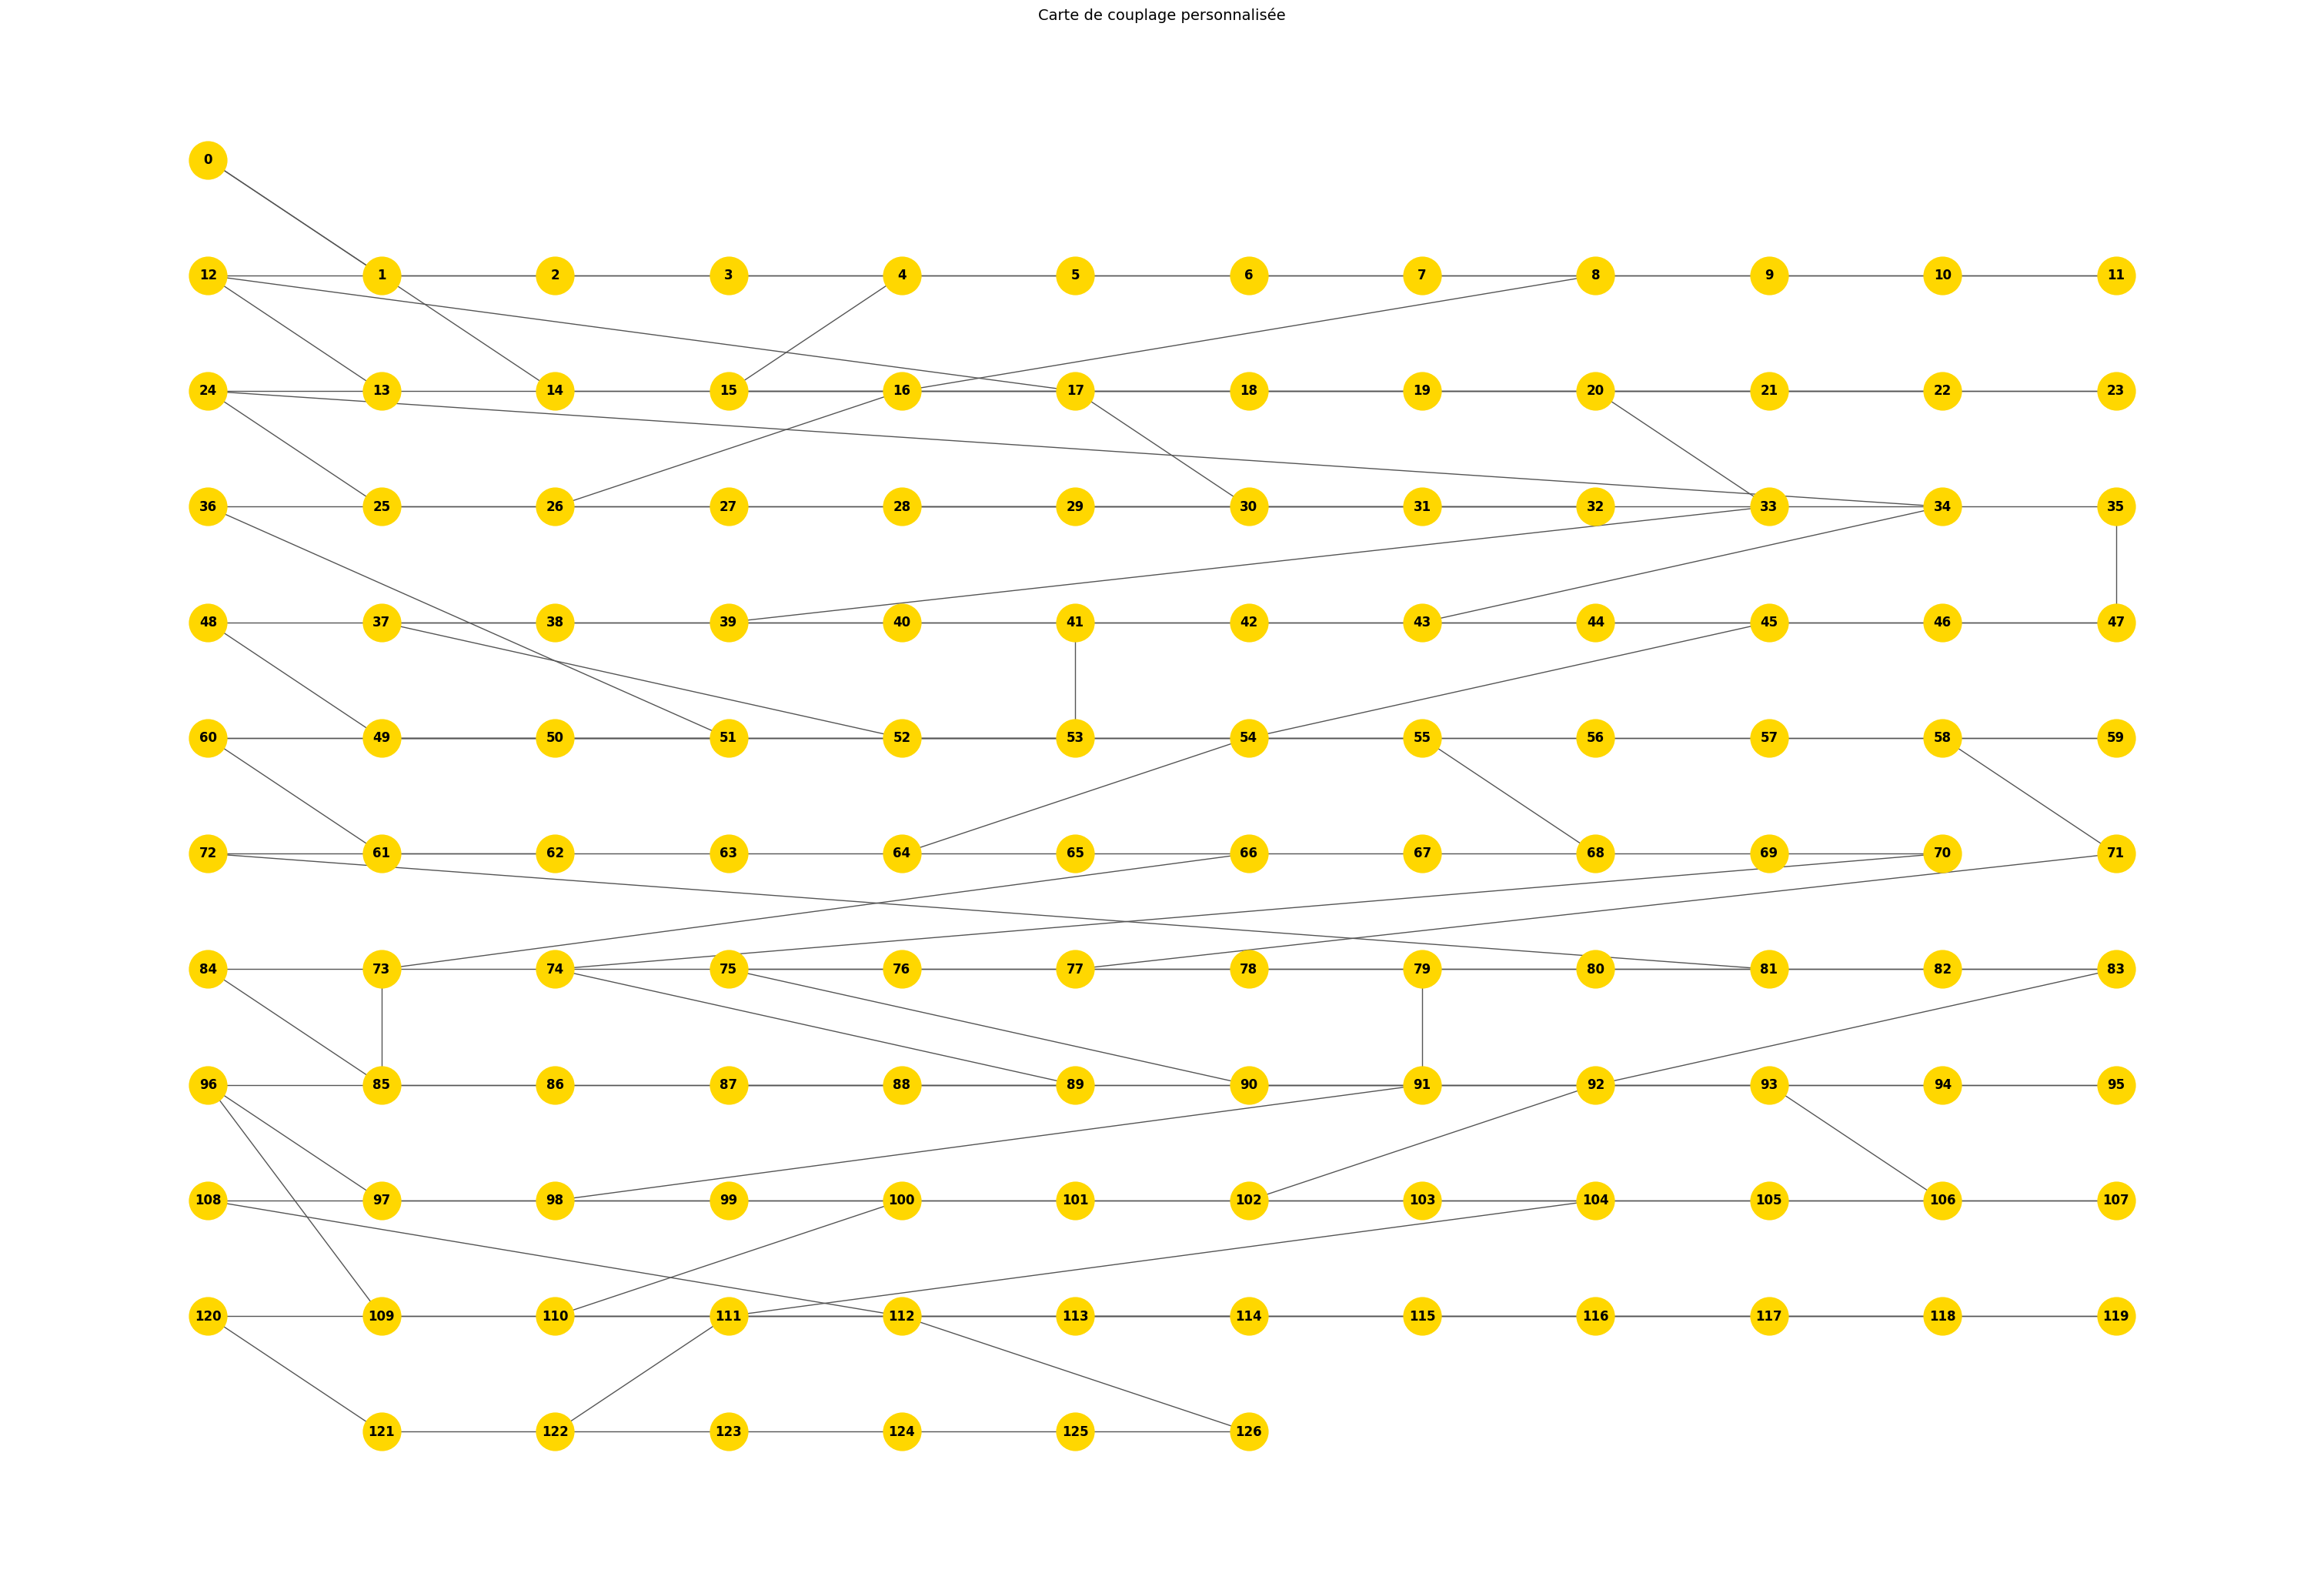

In [65]:
import matplotlib.pyplot as plt
import networkx as nx
import math

# Exemple de topologie (remplace avec celle de ton backend réel)
#coupling_map = [[0, 1], [1, 2], [0, 3], [1, 4], [2, 5], [3, 4], [4, 5]]
#num_qubits = 6
cols = math.ceil(math.sqrt(num_qubits))
qubit_coords = {i: (i % cols, -i // cols) for i in range(num_qubits)}  # Y négatif pour lisibilité

# Créer le graphe
G = nx.Graph()
G.add_nodes_from(qubit_coords.keys())
G.add_edges_from(coupling_map)

# Paramètres de style
node_color = "#FFD700"  # or
edge_color = "#555555"  # gris foncé
label_color = "black"

# Dessin
plt.figure(figsize=(30, 20))
nx.draw(
    G,
    pos=qubit_coords,
    with_labels=True,
    node_color=node_color,
    edge_color=edge_color,
    node_size=1200,
    font_size=12,
    font_color=label_color,
    linewidths=1.5,
    font_weight="bold"
)

plt.title("Carte de couplage personnalisée", fontsize=14)
plt.axis("off")
plt.tight_layout()
plt.savefig("C:\\Users\\m-ela.NINO\\Documents\\custom_coupling_map.png", dpi=300)
plt.show()


In [90]:
pip install qiskit-qasm3-import

   ---------------------------------------- 0.0/541.5 kB ? eta -:--:--
   ---------------------------------------- 541.5/541.5 kB 5.8 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
